# Superstore - Sales, Profit & Loss Risk

### A practical retail analytics and machine learning project

**Business question:** Can we predict profit and identify loss-making order lines from sales information?

We explore sales, discounts, product categories, and profitability. Then we solve two machine learning tasks: profit regression and loss classification.

This project is relevant to retail, e-commerce, sales analytics, pricing, and data science. It can support discount discussions, but it does not measure marketing campaign effectiveness.

**Dataset:** [Superstore on Kaggle](https://www.kaggle.com/datasets/vivek468/superstore-dataset-final)

**Data Dictionary**



| Column | Meaning | Project role |
|---|---|---|
| Row ID | Unique row identifier | Quality check; excluded from X |
| Order ID | Order identifier | Order-line and split checks |
| Order Date | Date the order was placed | Temporal split and calendar features |
| Ship Date | Recorded shipping date | Quality check; excluded from X |
| Ship Mode | Shipping service | Categorical feature |
| Customer ID | Customer identifier | Excluded from this first model |
| Customer Name | Customer name | Excluded from X |
| Segment | Customer segment | Categorical feature |
| Country | Country | Excluded because it is constant |
| City | City | Excluded from this first model |
| State | State | Categorical feature |
| Postal Code | Location code, not a quantity | Excluded from this first model |
| Region | Sales region | Categorical feature |
| Product ID | Product identifier | Excluded from this first model |
| Category | Main product category | Categorical feature |
| Sub-Category | Product sub-category | Categorical feature |
| Product Name | Product description | Excluded from this first model |
| Sales | Net sales amount for the line | Numeric feature |
| Quantity | Units sold | Numeric feature |
| Discount | Discount rate; 0.20 means 20% | Numeric feature |
| Profit | Line profit; negative values mean loss | Regression target; excluded from X |

Customer and product identifiers are deliberately excluded for a compact first model. They are not universally invalid features. Repeat-customer performance and unseen-product generalization would require separate experiments

### Business Understanding

Each row is an **order line**, not an entire order. One order can contain several product lines.

| Task | Target | Meaning | Main metric |
|---|---|---|---|
| Regression | `Profit` | Profit amount per order line | MAE |
| Classification | `Loss_Flag` | 1 = loss; 0 = no loss | F1 for the loss class |

We assume sales amount, quantity, planned discount, category, and region are known when an order is created. Profit is still unknown. `Profit` and profit-derived columns never enter X. Actual shipping date is excluded too.

A zero-profit line is **no loss**, not necessarily profitable. R² is not an accuracy percentage. We compare models with simple baselines instead of promising a fixed success rate.

## Project Overview

| Section | Purpose | Output |
|---|---|---|
| Data preparation | Load, check, and prepare the local CSV | Clean data and features |
| EDA | Explore the training data once | Distributions, comparisons, trends, and relationships |
| Regression | Predict profit per order line | MAE, MSE, RMSE, R² and Actual vs. Predicted |
| Classification | Predict whether an order line makes a loss | Accuracy, Precision, Recall, F1 and Confusion Matrix |
| Business review | Interpret results | Predictions, business insights, and limitations |

For each task: compare models on **2016 validation data**, select the best, refit on **2014–2016**, and evaluate once on **2017 test data**.

### Libraries

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style='whitegrid', palette=['#6D5BD0', '#2AA198', '#E6A44C'])
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor, DecisionTreeClassifier
from sklearn.ensemble import ExtraTreesRegressor, RandomForestClassifier
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.metrics import confusion_matrix


### Data Loading

Read the local CSV into a Pandas DataFrame. The CSV should be in the same folder as this notebook. `encoding='cp1252'` handles the special characters in this supplied file; the default UTF-8 encoding cannot read it correctly

In [2]:
df = pd.read_csv('Sample - Superstore.csv', encoding='cp1252')
df.head()

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2,0.00,41.9136
1,2,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3,0.00,219.5820
2,3,CA-2016-138688,6/12/2016,6/16/2016,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,90036,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2,0.00,6.8714
3,4,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5,0.45,-383.0310
4,5,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2,0.20,2.5164


### Data Overview

In [3]:
df.shape

(9994, 21)

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 9994 entries, 0 to 9993
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Row ID         9994 non-null   int64  
 1   Order ID       9994 non-null   str    
 2   Order Date     9994 non-null   str    
 3   Ship Date      9994 non-null   str    
 4   Ship Mode      9994 non-null   str    
 5   Customer ID    9994 non-null   str    
 6   Customer Name  9994 non-null   str    
 7   Segment        9994 non-null   str    
 8   Country        9994 non-null   str    
 9   City           9994 non-null   str    
 10  State          9994 non-null   str    
 11  Postal Code    9994 non-null   int64  
 12  Region         9994 non-null   str    
 13  Product ID     9994 non-null   str    
 14  Category       9994 non-null   str    
 15  Sub-Category   9994 non-null   str    
 16  Product Name   9994 non-null   str    
 17  Sales          9994 non-null   float64
 18  Quantity       9994

In [5]:
df.describe()

,Row ID,Postal Code,Sales,Quantity,Discount,Profit
count,9994.000000,9994.000000,9994.000000,9994.000000,9994.000000,9994.000000
mean,4997.500000,55190.379428,229.858001,3.789574,0.156203,28.656896
std,2885.163629,32063.693350,623.245101,2.225110,0.206452,234.260108
min,1.000000,1040.000000,0.444000,1.000000,0.000000,-6599.978000
25%,2499.250000,23223.000000,17.280000,2.000000,0.000000,1.728750
50%,4997.500000,56430.500000,54.490000,3.000000,0.200000,8.666500
75%,7495.750000,90008.000000,209.940000,5.000000,0.200000,29.364000
max,9994.000000,99301.000000,22638.480000,14.000000,0.800000,8399.976000


## Data Checks & Cleaning

Data quality means checking whether the data are usable: missing values, duplicate rows, and valid dates. Cleaning means fixing a confirmed problem. This supplied file has no missing values or exact duplicate rows, so no filling is needed. If those checks change with a new file, review the results before modelling.

In [6]:
df.isnull().sum()

Row ID           0
Order ID         0
Order Date       0
Ship Date        0
Ship Mode        0
Customer ID      0
Customer Name    0
Segment          0
Country          0
City             0
State            0
Postal Code      0
Region           0
Product ID       0
Category         0
Sub-Category     0
Product Name     0
Sales            0
Quantity         0
Discount         0
Profit           0
dtype: int64

In [7]:
df.duplicated().sum()

np.int64(0)

In [8]:
df = df.drop_duplicates().copy()
df['Order Date'] = pd.to_datetime(df['Order Date'], format='%m/%d/%Y')
df['Ship Date'] = pd.to_datetime(df['Ship Date'], format='%m/%d/%Y')

In [9]:
print('Date range:', df['Order Date'].min().date(), 'to', df['Order Date'].max().date())
print('Order lines:', len(df), '| Unique orders:', df['Order ID'].nunique())

Date range: 2014-01-03 to 2017-12-30
Order lines: 9994 | Unique orders: 5009


## Feature Engineering

Create a small number of useful columns. `Unit_Sales` is net sales per unit, not list price. `Sales_x_Discount` combines sales amount with discount. Year is used to split the data; month is a predictor. `Loss_Flag` is the classification target and is excluded from X.

In [10]:
df['Year'] = df['Order Date'].dt.year
df['Month'] = df['Order Date'].dt.month
df['Unit_Sales'] = df['Sales'] / df['Quantity']
df['Sales_x_Discount'] = df['Sales'] * df['Discount']
df['Loss_Flag'] = (df['Profit'] < 0).astype(int)

In [11]:
df[['Sales', 'Quantity', 'Discount', 'Unit_Sales', 'Profit', 'Loss_Flag']].head()

,Sales,Quantity,Discount,Unit_Sales,Profit,Loss_Flag
0,261.9600,2,0.00,130.9800,41.9136,0
1,731.9400,3,0.00,243.9800,219.5820,0
2,14.6200,2,0.00,7.3100,6.8714,0
3,957.5775,5,0.45,191.5155,-383.0310,1
4,22.3680,2,0.20,11.1840,2.5164,0


## Train / Validation / Test

**2014–2015: train** · **2016: validation** · **2017: test**

Learn from earlier years and evaluate on a later year. Validation selects the model; test gives the final evaluation. The date check below should return **1**: all lines of an order share one date and stay in the same split.

Customers and products may recur across years. This measures future transactions of the same business.

In [12]:
train = df[df['Year'] <= 2015].copy()
valid = df[df['Year'] == 2016].copy()
test = df[df['Year'] == 2017].copy()
print('Train:', len(train), '| Validation:', len(valid), '| Test:', len(test))

Train: 4095 | Validation: 2587 | Test: 3312


In [13]:
# Each order should have exactly one order date.
df.groupby('Order ID')['Order Date'].nunique().max()

1

## EDA — Explore the Training Data

EDA means **Exploratory Data Analysis**. Use training data to understand distributions and relationships without inspecting the final test year for model choices. Do not automatically delete extreme profits or losses: they may be important business cases.

### Profit Distribution

Negative values represent losses. Most lines have small profits, while a few have large gains or losses. A log count scale makes small bins easier to see.

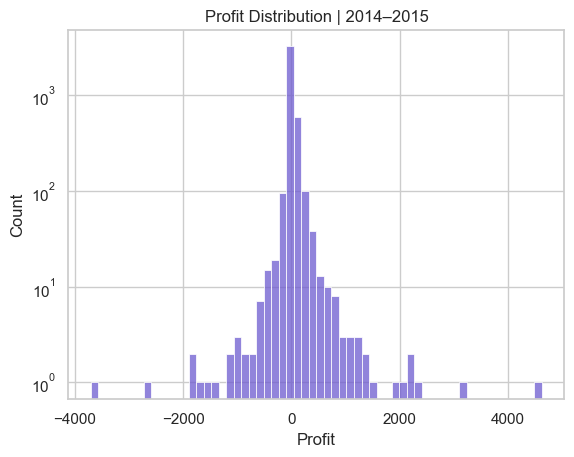

In [14]:
sns.histplot(data=train, x='Profit', bins=60, color='#6D5BD0')
plt.yscale('log')
plt.title('Profit Distribution | 2014–2015')
plt.show()

### Which Categories Generate Profit?

Compare total sales and total profit separately. A category with high revenue may still have low profit.

In [15]:
train.groupby('Category')[['Sales', 'Profit']].sum().round(2)

,Sales,Profit
Category,,
Furniture,327711.09,8472.93
Office Supplies,289009.88,47692.95
Technology,338059.04,54996.70


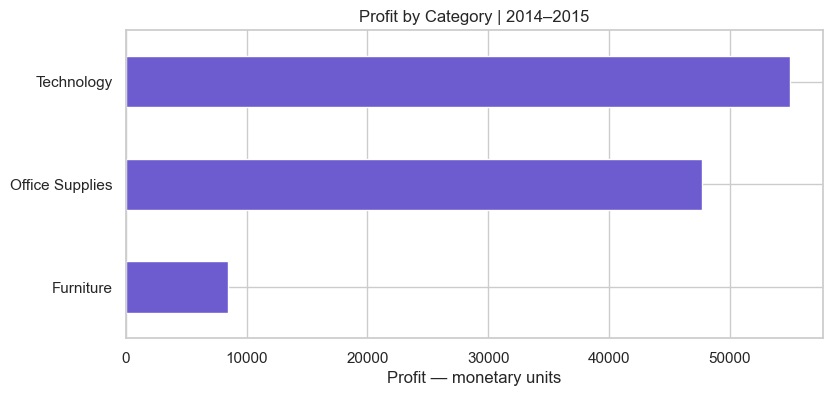

In [16]:
category_profit = train.groupby('Category')['Profit'].sum().sort_values()
category_profit.plot.barh(color='#6D5BD0', figsize=(9, 4))
plt.title('Profit by Category | 2014–2015')
plt.xlabel('Profit — monetary units')
plt.ylabel('')
plt.show()

### Which Sub-categories Need Attention?

Look for negative total profit, not only high sales volume. This chart identifies product groups worth reviewing.

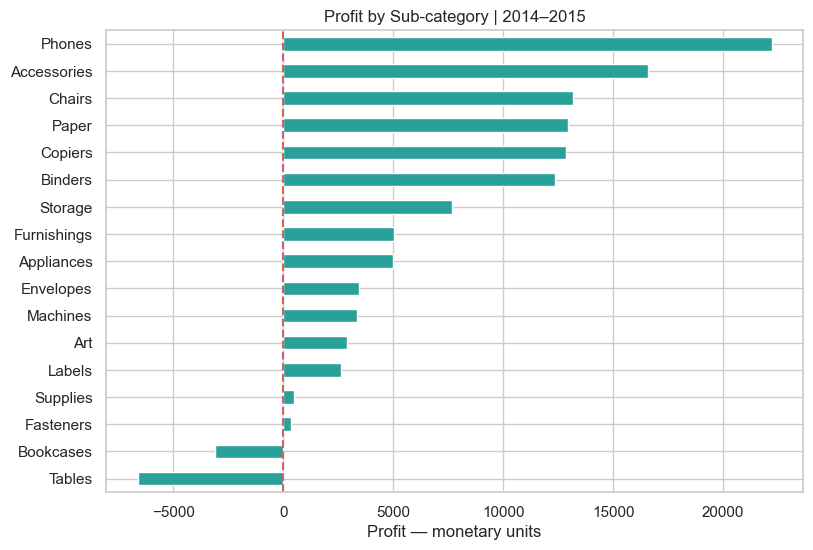

In [17]:
subcategory_profit = train.groupby('Sub-Category')['Profit'].sum().sort_values()
subcategory_profit.plot.barh(color='#2AA198', figsize=(9, 6))
plt.axvline(0, color='#CB6464', linestyle='--')
plt.title('Profit by Sub-category | 2014–2015')
plt.xlabel('Profit — monetary units')
plt.ylabel('')
plt.show()

### Monthly Sales & Profit

Observe changes over time. A sales peak does not necessarily produce a similar profit peak.

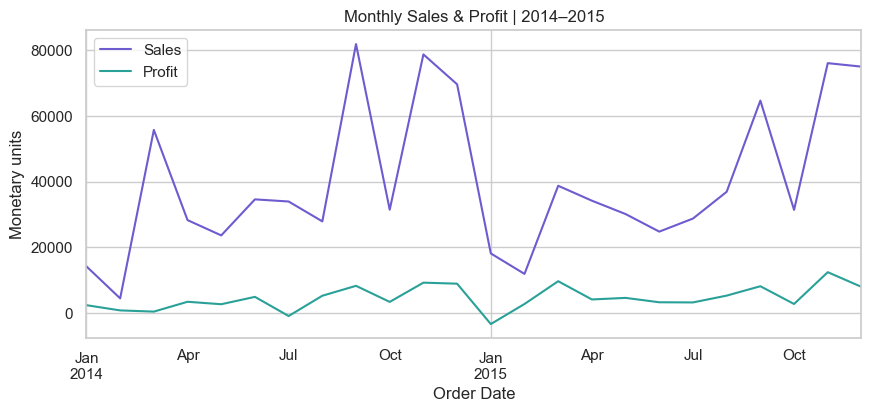

In [18]:
monthly = train.set_index('Order Date').resample('MS')[['Sales', 'Profit']].sum()
monthly.plot(color=['#6D5BD0', '#2AA198'], figsize=(10, 4))
plt.title('Monthly Sales & Profit | 2014–2015')
plt.ylabel('Monetary units')
plt.show()

### Discount & Profit

Inspect the relationship by category. This is observational: product mix and other factors may influence both discount and profit. The chart does not prove that changing a discount causes a specific profit increase.

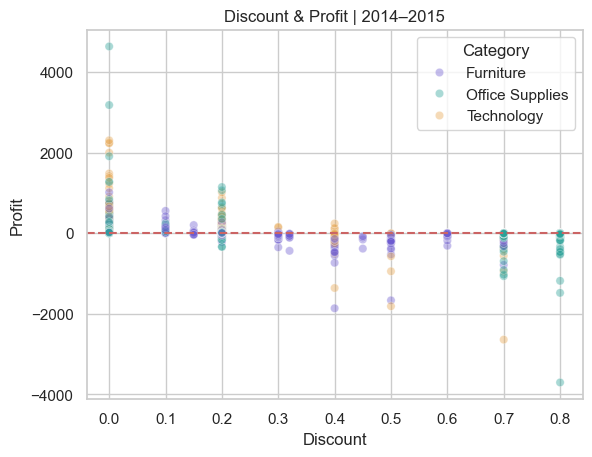

In [19]:
sns.scatterplot(data=train, x='Discount', y='Profit', hue='Category', alpha=0.4)
plt.axhline(0, color='#CB6464', linestyle='--')
plt.title('Discount & Profit | 2014–2015')
plt.show()

### Correlation

Correlation shows linear relationships, not causation. A low correlation does not automatically make a feature useless for a tree model.

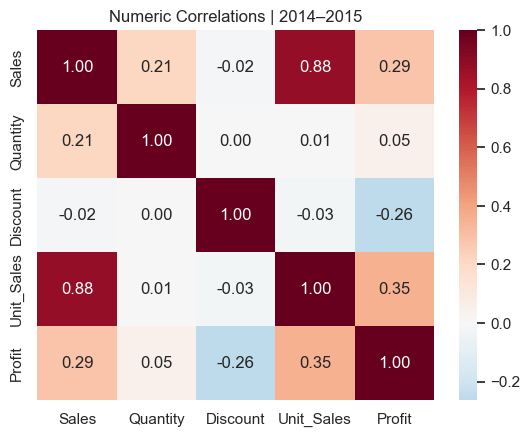

In [20]:
columns = ['Sales', 'Quantity', 'Discount', 'Unit_Sales', 'Profit']
sns.heatmap(train[columns].corr(), annot=True, fmt='.2f', cmap='RdBu_r', center=0)
plt.title('Numeric Correlations | 2014–2015')
plt.show()

## Prepare X — Features

Choose a compact feature set. `pd.get_dummies()` converts text categories into numeric columns, as in the learning notebooks. Use **all dummy columns** so each category has an explicit column. Align validation and test columns with training columns; categories absent from training become all-zero indicators.

No target column enters X. These models do not require scaling. The selected predictors have no missing values in this supplied dataset, so imputation is unnecessary here.

In [21]:
features = ['Sales', 'Quantity', 'Discount', 'Unit_Sales', 'Sales_x_Discount',
            'Month', 'Category', 'Sub-Category', 'Region', 'State', 'Segment', 'Ship Mode']
x_train = pd.get_dummies(train[features], dtype=int)
x_valid = pd.get_dummies(valid[features], dtype=int)
x_test = pd.get_dummies(test[features], dtype=int)

In [22]:
x_valid = x_valid.reindex(columns=x_train.columns, fill_value=0)
x_test = x_test.reindex(columns=x_train.columns, fill_value=0)
x_train.head()

,Sales,Quantity,Discount,Unit_Sales,Sales_x_Discount,Month,Category_Furniture,Category_Office Supplies,Category_Technology,Sub-Category_Accessories,...,State_Virginia,State_Washington,State_Wisconsin,Segment_Consumer,Segment_Corporate,Segment_Home Office,Ship Mode_First Class,Ship Mode_Same Day,Ship Mode_Second Class,Ship Mode_Standard Class
3,957.5775,5,0.45,191.5155,430.909875,10,1,0,0,0,...,0,0,0,1,0,0,0,0,0,1
4,22.3680,2,0.20,11.1840,4.473600,10,0,1,0,0,...,0,0,0,1,0,0,0,0,0,1
5,48.8600,7,0.00,6.9800,0.000000,6,1,0,0,0,...,0,0,0,1,0,0,0,0,0,1
6,7.2800,4,0.00,1.8200,0.000000,6,0,1,0,0,...,0,0,0,1,0,0,0,0,0,1
7,907.1520,6,0.20,151.1920,181.430400,6,0,0,1,0,...,0,0,0,1,0,0,0,0,0,1


## Regression — Predict Profit

**Target:** `Profit`. Compare Linear Regression, Decision Tree, and Extra Trees with a compact `algo_test` pattern from the lesson. The final test follows directly in this section.

| Metric | Meaning | Better |
|---|---|---|
| MAE | Average absolute prediction error | Lower |
| MSE | Average squared prediction error | Lower |
| RMSE | Square root of MSE, in profit units | Lower |
| R² | Performance relative to predicting the mean | Higher |

Select by **validation MAE** using unrounded scores. The median baseline is a reference, not a candidate model.

In [23]:
y_train = train['Profit']
y_valid = valid['Profit']
y_test = test['Profit']

### Metric Table

This small helper calculates all four metrics together. RMSE requires the square root of MSE.

In [24]:
def regression_scores(actual, predicted):
    mse = mean_squared_error(actual, predicted)
    return [mean_absolute_error(actual, predicted), mse, mse ** 0.5,
            r2_score(actual, predicted)]

reg_columns = ['MAE', 'MSE', 'RMSE', 'R²']

### Algo Test — Validation

Train each model, predict the validation data, and collect the scores in one table.

In [25]:
reg_models = {
    'Linear Regression': LinearRegression(),
    'Decision Tree': DecisionTreeRegressor(max_depth=8, min_samples_leaf=5, random_state=42),
    'Extra Trees': ExtraTreesRegressor(n_estimators=150, min_samples_leaf=2, random_state=42, n_jobs=-1)
}

def algo_test_regression(models, x_train, y_train, x_valid, y_valid):
    results = []
    for name, model in models.items():
        model.fit(x_train, y_train)
        predicted = model.predict(x_valid)
        results.append([name] + regression_scores(y_valid, predicted))
    return pd.DataFrame(results, columns=['Model'] + reg_columns).set_index('Model')

reg_results = algo_test_regression(reg_models, x_train, y_train, x_valid, y_valid)
reg_results = reg_results.sort_values('MAE')

In [26]:
baseline_prediction = [y_train.median()] * len(y_valid)
reg_baseline = pd.DataFrame([regression_scores(y_valid, baseline_prediction)],
                            index=['Median baseline'], columns=reg_columns)
pd.concat([reg_baseline, reg_results]).round(3)

,MAE,MSE,RMSE,R²
Median baseline,58.248,79327.207,281.651,-0.007
Extra Trees,23.469,31353.642,177.070,0.602
Decision Tree,35.431,37720.020,194.216,0.521
Linear Regression,40.114,20498.256,143.172,0.740


In [27]:
best_reg_name = reg_results.index[0]
profit_model = reg_models[best_reg_name]
print('Selected model:', best_reg_name)

Selected model: Extra Trees


### Regression — Final Test

Refit the selected model on 2014–2016. Compare it with the median baseline on the untouched 2017 data; the test does not select the model.

In [28]:
x_development = pd.concat([x_train, x_valid])
y_development = pd.concat([y_train, y_valid])
profit_model.fit(x_development, y_development)
profit_prediction = profit_model.predict(x_test)

In [29]:
test_baseline_profit = [y_development.median()] * len(y_test)
reg_test_results = pd.DataFrame(
    [regression_scores(y_test, test_baseline_profit),
     regression_scores(y_test, profit_prediction)],
    index=['Median baseline', best_reg_name], columns=reg_columns)
reg_test_results.round(3)

,MAE,MSE,RMSE,R²
Median baseline,58.230,58857.662,242.606,-0.006
Extra Trees,18.764,13121.287,114.548,0.776


### Actual vs Predicted Profit

Points close to the diagonal indicate more accurate predictions. Large errors matter even when the average error is low.

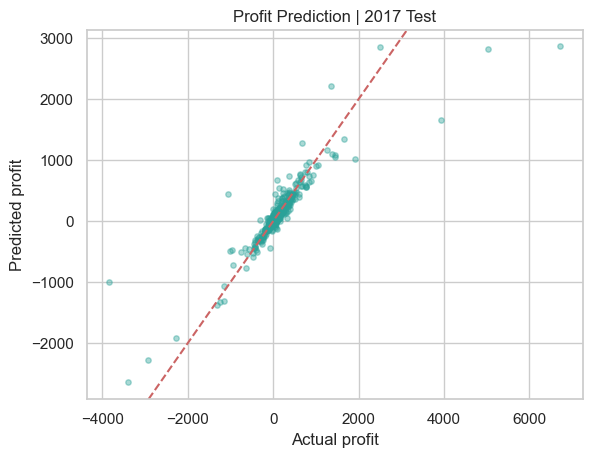

In [30]:
plt.scatter(y_test, profit_prediction, color='#2AA198', alpha=0.4, s=15)
plt.axline((0, 0), slope=1, color='#CB6464', linestyle='--')
plt.xlabel('Actual profit')
plt.ylabel('Predicted profit')
plt.title('Profit Prediction | 2017 Test')
plt.show()

## Classification — Predict Loss Risk

**Target:** `Loss_Flag`: **1 = loss**, **0 = no loss**. Compare Decision Tree and Random Forest using the same short fit → predict → table pattern.

| Metric | Meaning | Better |
|---|---|---|
| Accuracy | Share of all lines classified correctly | Higher |
| Precision | Share of loss alerts that are real losses | Higher |
| Recall | Share of actual losses detected | Higher |
| F1 | Balance between loss precision and recall | Higher |

Select by **validation loss-class F1**, using unrounded scores. Precision, Recall, and F1 refer to **loss (1)** rather than a micro average across classes. Keep the default decision threshold. The majority-class baseline can have high accuracy while missing all losses.

In [31]:
y_train_class = train['Loss_Flag']
y_valid_class = valid['Loss_Flag']
y_test_class = test['Loss_Flag']
y_train_class.value_counts(normalize=True)

Loss_Flag
0    0.810989
1    0.189011
Name: proportion, dtype: float64

### Metric Table

Calculate the four classification metrics together. A score is reported as zero when no positive predictions exist.

In [32]:
def classification_scores(actual, predicted):
    return [accuracy_score(actual, predicted),
            precision_score(actual, predicted, zero_division=0),
            recall_score(actual, predicted, zero_division=0),
            f1_score(actual, predicted, zero_division=0)]

class_columns = ['Accuracy', 'Precision', 'Recall', 'F1']

### Algo Test — Validation

In [33]:
class_models = {
    'Decision Tree': DecisionTreeClassifier(max_depth=8, min_samples_leaf=15,
                                          class_weight='balanced', random_state=42),
    'Random Forest': RandomForestClassifier(n_estimators=150, min_samples_leaf=3,
                                           class_weight='balanced', random_state=42, n_jobs=-1)
}

def algo_test_classification(models, x_train, y_train, x_valid, y_valid):
    results = []
    for name, model in models.items():
        model.fit(x_train, y_train)
        predicted = model.predict(x_valid)
        results.append([name] + classification_scores(y_valid, predicted))
    return pd.DataFrame(results, columns=['Model'] + class_columns).set_index('Model')

class_results = algo_test_classification(class_models, x_train, y_train_class, x_valid, y_valid_class)
class_results = class_results.sort_values('F1', ascending=False)

In [34]:
class_baseline = [y_train_class.mode()[0]] * len(y_valid_class)
class_baseline_results = pd.DataFrame([classification_scores(y_valid_class, class_baseline)],
                                      index=['Majority baseline'], columns=class_columns)
pd.concat([class_baseline_results, class_results]).round(3)

,Accuracy,Precision,Recall,F1
Majority baseline,0.816,0.000,0.000,0.000
Random Forest,0.936,0.777,0.914,0.840
Decision Tree,0.908,0.678,0.960,0.794


In [35]:
best_class_name = class_results.index[0]
loss_model = class_models[best_class_name]
print('Selected model:', best_class_name)

Selected model: Random Forest


### Classification — Final Test

Refit on 2014–2016 and evaluate on 2017. The same four metrics now describe the selected model on new data.

In [36]:
y_development_class = pd.concat([y_train_class, y_valid_class])
loss_model.fit(x_development, y_development_class)
loss_prediction = loss_model.predict(x_test)

In [37]:
test_class_baseline = [y_development_class.mode()[0]] * len(y_test_class)
class_test_results = pd.DataFrame(
    [classification_scores(y_test_class, test_class_baseline),
     classification_scores(y_test_class, loss_prediction)],
    index=['Majority baseline', best_class_name], columns=class_columns)
class_test_results.round(3)

,Accuracy,Precision,Recall,F1
Majority baseline,0.813,0.000,0.000,0.00
Random Forest,0.934,0.767,0.929,0.84


### Confusion Matrix

Rows show actual classes; columns show predicted classes.

| | Predicted no loss | Predicted loss |
|---|---|---|
| Actual no loss | TN: correct no alert | FP: false loss alert |
| Actual loss | FN: missed loss | TP: detected loss |

Both missed losses and unnecessary alerts matter. Their costs should guide a future threshold experiment using validation data.

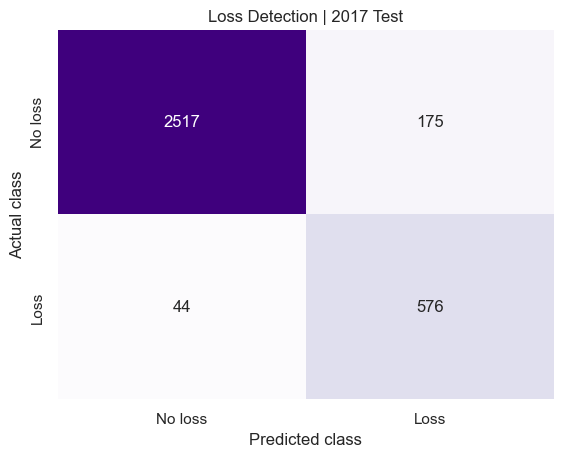

In [38]:
sns.heatmap(confusion_matrix(y_test_class, loss_prediction), annot=True, fmt='d', cmap='Purples',
            xticklabels=['No loss', 'Loss'], yticklabels=['No loss', 'Loss'], cbar=False)
plt.grid(False)
plt.xlabel('Predicted class')
plt.ylabel('Actual class')
plt.title('Loss Detection | 2017 Test')
plt.show()

## Prediction Review

Compare actual and predicted values for a few historical test lines. This is an evaluation table, not a live order recommendation.

In [39]:
review = test[['Sales', 'Discount', 'Category', 'Profit', 'Loss_Flag']].copy()
review['Predicted_Profit'] = profit_prediction
review['Predicted_Loss'] = loss_prediction
review.head(10).round(2)

,Sales,Discount,Category,Profit,Loss_Flag,Predicted_Profit,Predicted_Loss
12,15.55,0.2,Office Supplies,5.44,0,5.47,0
23,71.37,0.3,Furniture,-1.02,1,-14.35,1
34,29.47,0.2,Office Supplies,9.95,0,9.86,0
41,147.17,0.2,Technology,16.56,0,18.33,0
43,95.62,0.2,Office Supplies,9.56,0,-14.74,1
71,19.05,0.0,Office Supplies,8.76,0,9.25,0
75,1.25,0.8,Office Supplies,-1.93,1,-2.11,1
76,9.71,0.6,Furniture,-5.82,1,-6.24,1
77,27.24,0.2,Office Supplies,2.72,0,1.79,0
84,230.38,0.2,Office Supplies,-48.95,1,-39.09,1


## Business Insights — Full-period Review

Model evaluation is finished. Now summarize the whole 2014–2017 period for business reporting. These tables do not feed back into model selection. Weighted margin is **total profit / total sales**, not the average of line-level margins.

In [40]:
print('Total sales:', round(df['Sales'].sum(), 2))
print('Total profit:', round(df['Profit'].sum(), 2))
print('Weighted margin (%):', round(df['Profit'].sum() / df['Sales'].sum() * 100, 2))
print('Loss-making lines (%):', round(df['Loss_Flag'].mean() * 100, 2))

Total sales: 2297200.86
Total profit: 286397.02
Weighted margin (%): 12.47
Loss-making lines (%): 18.72


In [41]:
df.groupby('Category')[['Sales', 'Profit']].sum().round(2)

,Sales,Profit
Category,,
Furniture,741999.80,18451.27
Office Supplies,719047.03,122490.80
Technology,836154.03,145454.95


In [42]:
df.groupby('Region')[['Sales', 'Profit']].sum().round(2)

,Sales,Profit
Region,,
Central,501239.89,39706.36
East,678781.24,91522.78
South,391721.90,46749.43
West,725457.82,108418.45


In [43]:
df.groupby('Sub-Category')[['Sales', 'Profit']].sum().sort_values('Profit').round(2)

,Sales,Profit
Sub-Category,,
Tables,206965.53,-17725.48
Bookcases,114880.00,-3472.56
Supplies,46673.54,-1189.10
Fasteners,3024.28,949.52
Machines,189238.63,3384.76
Labels,12486.31,5546.25
Art,27118.79,6527.79
Envelopes,16476.40,6964.18
Furnishings,91705.16,13059.14


## Conclusion

We combined retail EDA, profit regression, and loss classification in one practical workflow. The final results below are calculated from the test predictions rather than written in advance.

In [44]:
print('Profit model:', best_reg_name)
print('Loss-risk model:', best_class_name)
print('Actual losses detected (%):', round(class_test_results.loc[best_class_name, 'Recall'] * 100, 1))

Profit model: Extra Trees
Loss-risk model: Random Forest
Actual losses detected (%): 92.9


**Business interpretation:** Investigate weak sub-categories together with product costs, discounts, and regional mix. A prediction can help prioritize a human review; it does not justify automatically rejecting an order. Observed discount relationships are not causal estimates.

**Limitations:** One historical dataset and one validation year. Some large profit errors remain. New-customer and new-product performance are not separately measured. The selected feature set has no missing values in this file; a new dataset may need additional cleaning. These results do not guarantee future production performance.

**Possible next steps:** More temporal validation periods, error analysis for large transactions, and cost-based threshold selection. They are future extensions, not completed features.

Technology generated the highest total profit, while Tables, Bookcases, and Supplies recorded overall losses.

